# The full tower: front, back, left and right

The starter notebook stops at the front and back. Each cube picks 1 of 3 opposite pairs, the circuit uses 12 qubits, and constrained QAOA finds a good front/back pick about 28% of the time.

A finished tower also picks the left and right, and that pair has to be a **different** one. Each cube then has \(3 \times 2 = 6\) choices. This notebook keeps the starter's idea and widens it from 3 choices to 6:

- one qubit per choice, so 6 qubits per cube and 24 in total
- a W state, an equal spread over the 6 choices
- an XY mixer, which moves that single 1 and never creates a second one
- the same colour rule as the starter, now on both axes

A valid shot always has exactly one 1 in each block of six qubits. The "one pair cannot face two directions" rule is built into the 6 choices, so it does not need a penalty term. That is the lesson of the warm-up: put the rule in the circuit, not only in the cost.

Zero cost means both axes are 2-factors. For these four cubes there are two such picks: the solved tower and its quarter turn. `solves` checks the tower itself.


In [1]:
import itertools
import time

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import XXPlusYYGate
from qiskit.quantum_info import Operator, SparsePauliOp, Statevector
from qiskit_aer import AerSimulator
from scipy.optimize import minimize

from resources.helpers import (
    SEED, draw_tower, plot_landscape, prepare, show, strip_marker, tower_from,
)

np.set_printoptions(linewidth=120, precision=4, suppress=True)


## Choices, cost, and the classical check

`CHOICES` is the list already in the starter: `(front/back pair, left/right pair)` with the two pairs different. A candidate is one index in `0..5` per cube.

The cost is only the colour rule. For each axis, every colour must be touched exactly twice. The one-hot rules and the double-duty rule are free, because every index in `0..5` already picks two different pairs.


In [2]:
COLOURS = "RGBY"
CUBES = [
    ["GR", "BR", "GY"],
    ["GY", "RB", "BY"],
    ["BR", "RG", "RY"],
    ["YR", "RG", "BG"],
]
CHOICES = list(itertools.permutations(range(3), 2))
MIX_PAIRS = list(itertools.combinations(range(6), 2))
LAMBDA, MU = 2, 2


def solves(tower):
    # True when each of the four sides shows every colour once.
    return all(len({view[side] for view in tower}) == len(tower) for side in range(4))


def colours_of(cubes):
    return sorted({ch for cube in cubes for pair in cube for ch in pair})


def starter_cost(cubes, x, y, colours=COLOURS):
    # The starter notebook's QUBO, copied so this file can check against it.
    total = 0
    for c in range(len(cubes)):
        total += LAMBDA * ((sum(x[c]) - 1) ** 2 + (sum(y[c]) - 1) ** 2)
        total += MU * sum(x[c][p] * y[c][p] for p in range(3))
    for picks in (x, y):
        for k in colours:
            degree = sum(
                cubes[c][p].count(k) * picks[c][p]
                for c in range(len(cubes)) for p in range(3)
            )
            total += (degree - 2) ** 2
    return total


def one_hot(pair):
    return [int(i == pair) for i in range(3)]


def cost_tensor(cubes):
    # Cost of every 6-choice assignment. Axis 0 is cube 0.
    n = len(cubes)
    total = np.zeros((6,) * n, dtype=float)
    for axis in (0, 1):
        for colour in colours_of(cubes):
            acc = None
            for c, cube in enumerate(cubes):
                weights = np.array(
                    [cube[CHOICES[k][axis]].count(colour) for k in range(6)],
                    dtype=float,
                )
                shape = [1] * n
                shape[c] = 6
                term = weights.reshape(shape)
                acc = term if acc is None else acc + term
            total += (acc - 2) ** 2
    return total


def tower_of(cubes, choice_indices):
    return tower_from(cubes, [CHOICES[k] for k in choice_indices])


cost = cost_tensor(CUBES)
good = np.isclose(cost, 0)
gaps = []
for index in itertools.product(range(6), repeat=len(CUBES)):
    x = [one_hot(CHOICES[k][0]) for k in index]
    y = [one_hot(CHOICES[k][1]) for k in index]
    gaps.append(abs(starter_cost(CUBES, x, y) - cost[index]))

print(f"{cost.size} feasible picks, {int(good.sum())} at cost 0, "
      f"next cost {np.unique(cost)[1]}")
print(f"largest gap versus the starter QUBO: {max(gaps)}")
for index in zip(*np.where(good)):
    tower = tower_of(CUBES, index)
    print(index, "solves" if solves(tower) else "FAIL", tower)


1296 feasible picks, 2 at cost 0, next cost 2.0
largest gap versus the starter QUBO: 0.0
(np.int64(3), np.int64(1), np.int64(4), np.int64(5)) solves [('B', 'G', 'R', 'Y'), ('Y', 'Y', 'G', 'B'), ('R', 'B', 'Y', 'R'), ('G', 'R', 'B', 'G')]
(np.int64(5), np.int64(4), np.int64(1), np.int64(3)) solves [('G', 'B', 'Y', 'R'), ('Y', 'Y', 'B', 'G'), ('B', 'R', 'R', 'Y'), ('R', 'G', 'G', 'B')]


Two picks score zero, and both pass `solves`. They are one tower and the quarter turn of it: the front of one is the right of the other. Every other feasible pick scores at least 2. On these 1,296 picks the degree cost matches the starter's full QUBO, which is the check that dropping the penalty terms did not change the answers.


## The same cost as a Hamiltonian

Qubit `6c + k` is choice `k` of cube `c`. The operator below is the degree cost written with \(z = (1 - Z) / 2\). It is quadratic, so every term is a single Z or a ZZ, and the starter's `rz` / `rzz` cost layer still applies.

It agrees with the classical cost on every feasible one-hot bitstring. Outside that set (two 1s on one cube, for example) the circuit never goes, because the W state and the XY mixer stay at a single 1 per cube.


In [3]:
def choice_hamiltonian(cubes):
    letters = colours_of(cubes)
    n = 6 * len(cubes)
    one = SparsePauliOp("I" * n)

    def var(q):
        return SparsePauliOp.from_sparse_list([("", [], 0.5), ("Z", [q], -0.5)], n)

    H = 0 * one
    for axis in (0, 1):
        for colour in letters:
            degree = -2 * one
            for c, cube in enumerate(cubes):
                for k in range(6):
                    mult = cube[CHOICES[k][axis]].count(colour)
                    if mult:
                        degree += mult * var(6 * c + k)
            H += degree @ degree
    return H.simplify()


def energy(H, bits):
    # Value of a Z-only Hamiltonian. bits[q] is qubit q. Qiskit stores qubit 0 last in a label.
    total = 0.0
    for label, coeff in zip(H.paulis.to_labels(), H.coeffs):
        sign = 1
        for q, op in enumerate(reversed(label)):
            if op == "Z" and bits[q]:
                sign = -sign
        total += float(coeff.real) * sign
    return total


H = choice_hamiltonian(CUBES)
weight = max(label.count("Z") for label in H.paulis.to_labels())
gaps = []
for index in itertools.product(range(6), repeat=len(CUBES)):
    bits = [0] * H.num_qubits
    for c, k in enumerate(index):
        bits[6 * c + k] = 1
    gaps.append(abs(energy(H, bits) - cost[index]))
print(f"{H.num_qubits} qubits, {len(H)} Pauli terms, largest term has {weight} Z")
print(f"largest |H - cost| on all {cost.size} feasible picks: {max(gaps):.1e}")


24 qubits, 290 Pauli terms, largest term has 2 Z
largest |H - cost| on all 1296 feasible picks: 0.0e+00


## W state and XY mixer

The warm-up prepares a W state on 3 qubits. The same split works for 6. Start with the token on qubit 0, then at each step keep amplitude \(1/\sqrt{6}\) on the qubit that already holds it and pass the rest on. The angles below are that split. The check is that each of the six one-hot strings has probability \(1/6\) and every other string has probability 0.

The mixer is the warm-up's XY mixer on every pair among the six qubits: `XXPlusYYGate(2β)`. On the one-hot strings that is a 6×6 unitary. The angle search uses that 6×6 matrix, four of them, one per cube. A full 24-qubit statevector is \(2^{24}\) amplitudes; the feasible space is \(6^4 = 1296\). The matrix is the same one the gates apply, so the probabilities are the probabilities of the real circuit.


In [4]:
def w_state(qc, qubits):
    # Equal superposition of the single-1 bitstrings.
    n = len(qubits)
    qc.x(qubits[0])
    for i in range(n - 1):
        remaining = n - i
        qc.cry(2 * np.arccos(1 / np.sqrt(remaining)), qubits[i], qubits[i + 1])
        qc.cx(qubits[i + 1], qubits[i])


check = QuantumCircuit(6)
w_state(check, range(6))
probs = np.abs(Statevector(check).data) ** 2
one_hot = probs[[1 << k for k in range(6)]]
print("one-hot probabilities", np.round(one_hot, 6), "other mass", float(probs.sum() - one_hot.sum()))


def xy_one_hot(beta):
    # XY mixer restricted to the six one-hot states.
    qc = QuantumCircuit(6)
    for i, j in MIX_PAIRS:
        qc.append(XXPlusYYGate(2 * beta), [i, j])
    full = Operator(qc).data
    keep = [1 << k for k in range(6)]
    return full[np.ix_(keep, keep)]


def apply_mixer(psi, unitary):
    for axis in range(psi.ndim):
        psi = np.moveaxis(psi, axis, -1)
        psi = np.matmul(psi, unitary.T)
        psi = np.moveaxis(psi, -1, axis)
    return psi


def qaoa_state(costs, gammas, betas):
    n = costs.ndim
    psi = np.full((6,) * n, 6 ** (-n / 2), dtype=complex)
    for gamma, beta in zip(gammas, betas):
        psi = psi * np.exp(-1j * gamma * costs)
        psi = apply_mixer(psi, xy_one_hot(beta))
    return psi


def average_and_hit(psi, costs, solved):
    probs = np.abs(psi) ** 2
    return float(np.sum(probs * costs)), float(probs[solved].sum())


one-hot probabilities [0.1667 0.1667 0.1667 0.1667 0.1667 0.1667] other mass 0.0


## Angles

One round first, on a grid, same as the warm-up. The cross on the heatmap is the lowest average cost. COBYLA then grows the circuit one round at a time, starting each new round from the previous angles. The objective is the average cost. It does not use the list of answers. On a shot device the same number is the mean of `starter_cost` over the measured bitstrings.


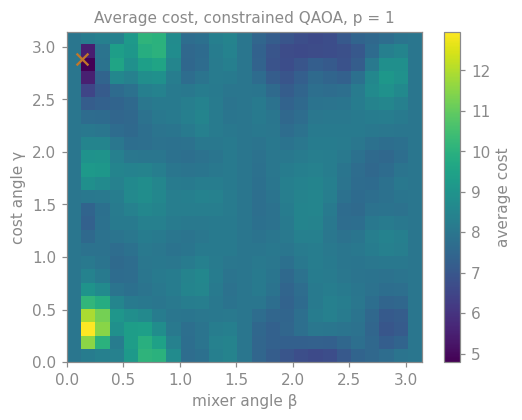

p=1 grid: average cost 4.787, P(solved) 0.96%
random feasible pick 0.154%, random 24-bit string 1.192e-07
p=1  average cost 4.745  P(solved) 0.88%


p=2  average cost 3.713  P(solved) 1.94%


p=3  average cost 3.302  P(solved) 3.14%


p=4  average cost 2.961  P(solved) 5.99%


p=5  average cost 2.684  P(solved) 9.94%


p=6  average cost 2.462  P(solved) 16.59%


p=7  average cost 2.122  P(solved) 26.35%
angles [3.0065 2.8849 2.8417 2.8075 2.7904 2.7529 2.6958 0.1967 0.1583 0.1415 0.1223 0.1072 0.0869 0.0633]


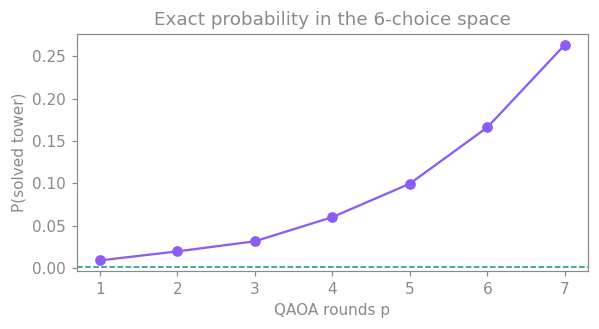

In [5]:
gammas = np.linspace(0, np.pi, 25)
betas = np.linspace(0, np.pi, 25)
avg = np.zeros((len(gammas), len(betas)))
hit = np.zeros_like(avg)
for i, gamma in enumerate(gammas):
    for j, beta in enumerate(betas):
        state = qaoa_state(cost, [gamma], [beta])
        avg[i, j], hit[i, j] = average_and_hit(state, cost, good)
i, j = np.unravel_index(avg.argmin(), avg.shape)
g1, b1 = float(gammas[i]), float(betas[j])
plot_landscape(avg, gammas, betas, (g1, b1))
print(f"p=1 grid: average cost {avg[i, j]:.3f}, P(solved) {hit[i, j]:.2%}")
print(f"random feasible pick {good.sum() / cost.size:.3%}, "
      f"random 24-bit string {good.sum() / 2 ** H.num_qubits:.3e}")


def train(p, x0, maxiter):
    def objective(x):
        state = qaoa_state(cost, x[:p], x[p:])
        return average_and_hit(state, cost, good)[0]

    result = minimize(objective, np.asarray(x0, dtype=float), method="COBYLA",
                      options={"maxiter": maxiter, "rhobeg": 0.35})
    state = qaoa_state(cost, result.x[:p], result.x[p:])
    mean, solved_p = average_and_hit(state, cost, good)
    print(f"p={p:d}  average cost {mean:.3f}  P(solved) {solved_p:.2%}")
    return result.x, solved_p, mean


angles, solved_p, mean = train(1, [g1, b1], maxiter=80)
curve = [(1, solved_p, mean)]
for p in range(2, 8):
    old_g, old_b = angles[: p - 1], angles[p - 1 :]
    start = np.concatenate([old_g, [old_g[-1]], old_b, [old_b[-1]]])
    angles, solved_p, mean = train(p, start, maxiter=220 if p < 5 else 400)
    curve.append((p, solved_p, mean))

print("angles", np.round(angles, 4))

fig, ax = __import__("matplotlib").pyplot.subplots(figsize=(6.0, 2.8))
ax.plot([p for p, _, _ in curve], [h for _, h, _ in curve], marker="o", color="#8B5CF6")
ax.axhline(good.sum() / cost.size, color="#0E9488", ls="--", lw=1)
ax.set_xlabel("QAOA rounds p")
ax.set_ylabel("P(solved tower)")
ax.set_title("Exact probability in the 6-choice space")
show(fig)


The dashed line is a uniform draw from the 1,296 feasible picks, about 0.15%. By seven rounds the exact probability is about a quarter. The average cost is still falling, so more rounds would likely do better, at the price of a deeper circuit. Seven rounds is the circuit measured below.

These probabilities are exact for the ideal circuit. The next cells build that circuit and sample it.


transpiled in 1.6s
qubits 24  depth 1503  cx 4610  ops {'cx': 4610, 'rz': 4255, 'sx': 2040, 'x': 4}


local Aer, 1000 shots, 32.4s, seed 7
valid one-hot shots 1000/1000
solved towers 255/1000 = 25.50%  (exact 26.35%)
random 24-bit baseline 0.000012%
random feasible baseline 0.154%
example [5, 4, 1, 3]


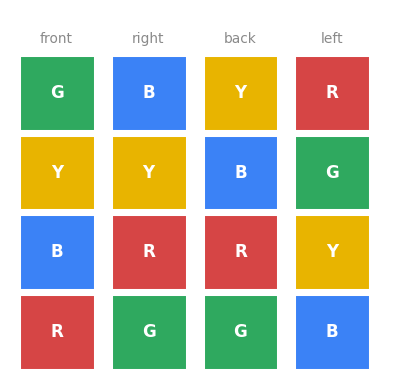

example [3, 1, 4, 5]


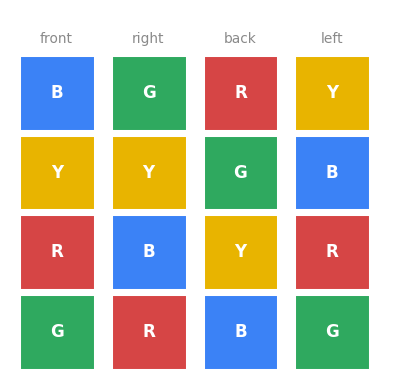

In [6]:
def cost_layer(qc, hamiltonian, gamma):
    # exp(-i gamma H) for Z and ZZ terms. Same gates as the starter.
    for label, coeff in zip(hamiltonian.paulis.to_labels(), hamiltonian.coeffs):
        qubits = [q for q, op in enumerate(reversed(label)) if op == "Z"]
        angle = 2 * float(gamma) * float(coeff.real)
        if len(qubits) == 1:
            qc.rz(angle, qubits[0])
        elif len(qubits) == 2:
            qc.rzz(angle, *qubits)


def tower_qaoa(cubes, hamiltonian, gammas, betas):
    qc = QuantumCircuit(6 * len(cubes))
    for c in range(len(cubes)):
        w_state(qc, list(range(6 * c, 6 * c + 6)))
    for gamma, beta in zip(gammas, betas):
        cost_layer(qc, hamiltonian, gamma)
        for c in range(len(cubes)):
            qubits = [6 * c + k for k in range(6)]
            for i, j in MIX_PAIRS:
                qc.append(XXPlusYYGate(2 * float(beta)), [qubits[i], qubits[j]])
    return qc


def choices_from_bitstring(bitstring, n_cubes):
    # Qiskit stores qubit 0 as the rightmost bit.
    bits = bitstring[::-1]
    choices = []
    for c in range(n_cubes):
        block = bits[6 * c: 6 * c + 6]
        if block.count("1") != 1:
            return None
        choices.append(block.index("1"))
    return choices


p = len(angles) // 2
circuit = tower_qaoa(CUBES, H, angles[:p], angles[p:])
t0 = time.perf_counter()
compiled = transpile(circuit, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1)
n_qubits = compiled.num_qubits
depth = compiled.depth()
n_cx = compiled.count_ops().get("cx", 0)
print(f"transpiled in {time.perf_counter() - t0:.1f}s")
print(f"qubits {n_qubits}  depth {depth}  cx {n_cx}  ops {dict(compiled.count_ops())}")

shots = 1000
compiled.measure_all()
t0 = time.perf_counter()
counts = AerSimulator(method="statevector", seed_simulator=SEED).run(
    compiled, shots=shots).result().get_counts()
print(f"local Aer, {shots} shots, {time.perf_counter() - t0:.1f}s, seed {SEED}")

solved_shots = valid_shots = 0
examples = []
for bitstring, nshots in counts.items():
    choice = choices_from_bitstring(bitstring, len(CUBES))
    if choice is None:
        continue
    valid_shots += nshots
    tower = tower_of(CUBES, choice)
    if solves(tower):
        solved_shots += nshots
        if len(examples) < 2 and tower not in [e[1] for e in examples]:
            examples.append((choice, tower, nshots))

random_bits = good.sum() / 2 ** (6 * len(CUBES))
random_valid = good.sum() / 6 ** len(CUBES)
print(f"valid one-hot shots {valid_shots}/{shots}")
print(f"solved towers {solved_shots}/{shots} = {solved_shots / shots:.2%}  "
      f"(exact {curve[-1][1]:.2%})")
print(f"random 24-bit baseline {random_bits:.6%}")
print(f"random feasible baseline {random_valid:.3%}")
for choice, tower, nshots in examples:
    print("example", choice)
    draw_tower(tower)


Every shot is a legal one-hot pick, which is the mixer doing its job. The shot rate sits on the exact probability. Both examples pass `solves`; they are the tower and its quarter turn.

Two baselines, because they answer different questions:

- a uniform random 24-bit string is a solved tower with probability \(2 / 2^{24}\), about 0.000012%. The rubric asks for this number.
- the circuit never leaves the 1,296 legal picks, and 2 of those are solved, so a random legal pick succeeds about 0.15% of the time. The QAOA probability should be compared with this one.

Brute force over the 331,776 orientations still finishes in a fraction of a second and finds all 8 facings. This circuit is not a faster solver. It is the full puzzle written in the same constrained-QAOA form as the warm-up, and it returns a correct tower on about 1 shot in 4.


In [7]:
def orientations(cube):
    views = []
    for a, b in itertools.permutations(range(3), 2):
        for fa in (0, 1):
            for fb in (0, 1):
                front, side = cube[a], cube[b]
                views.append((front[fa], front[1 - fa], side[fb], side[1 - fb]))
    return views


t0 = time.perf_counter()
winners = [tower for tower in itertools.product(*(orientations(c) for c in CUBES)) if solves(tower)]
print(f"brute force: {24 ** len(CUBES):,} orientations, {len(winners)} solved, "
      f"{time.perf_counter() - t0:.2f}s")
print("results row")
print(f"N=4 | 6-choice one-hot XY-QAOA p={p} | local Aer (SV1 not submitted yet) | "
      f"{n_qubits} qubits | {n_cx} cx | "
      f"depth {depth} | {shots} shots | "
      f"P={solved_shots / shots:.3f} exact {curve[-1][1]:.3f} | "
      f"random bitstring {random_bits:.3e} | job id: fill in after submit_job")


brute force: 331,776 orientations, 8 solved, 0.23s
results row
N=4 | 6-choice one-hot XY-QAOA p=7 | local Aer (SV1 not submitted yet) | 24 qubits | 4610 cx | depth 1503 | 1000 shots | P=0.255 exact 0.263 | random bitstring 1.192e-07 | job id: fill in after submit_job


## Sending it to SV1

`submit_job` is yours. The starter and `resources/02_qbraid_sdk.ipynb` use the same three steps: build a `QbraidProvider`, get the device `aws:aws:sim:sv1`, and `device.run`. Print the job id and return `job.result().data.get_counts()`.

Leave the `return None` in place until that works. The cell under it uses local Aer while the function returns nothing, and it does not send a second job by accident. Do not paste an API key into the notebook. A 24-qubit, depth-1500 circuit costs more than the warm-up's 0.375 credits, because SV1 bills 7.5 credits per minute of simulation.


In [8]:
SV1 = "aws:aws:sim:sv1"


def submit_job(qc, shots):
    """Run qc on SV1 and return its counts. Return None until this is filled in.

    1. provider = QbraidProvider()
    2. device = provider.get_device(SV1); print the status
    3. job = device.run(qc, shots=shots); print(job.id); return job.result().data.get_counts()
    """
    return None


prepared = prepare(tower_qaoa(CUBES, H, angles[:p], angles[p:]))
raw = submit_job(prepared, shots)
if raw is None:
    print("submit_job is still empty, so nothing was sent to SV1.")
    print("The Aer counts above are the local check. After submit_job returns counts,")
    print("strip_marker(raw) brings them back to Qiskit order.")
else:
    qbraid_counts = strip_marker(raw)
    qbraid_solved = 0
    for bitstring, nshots in qbraid_counts.items():
        choice = choices_from_bitstring(bitstring, len(CUBES))
        if choice is not None and solves(tower_of(CUBES, choice)):
            qbraid_solved += nshots
    total = sum(qbraid_counts.values())
    print(f"SV1 solved {qbraid_solved}/{total} = {qbraid_solved / total:.2%}")


submit_job is still empty, so nothing was sent to SV1.
The Aer counts above are the local check. After submit_job returns counts,
strip_marker(raw) brings them back to Qiskit order.


## Bonus: five and six cubes

The encoding does not change with the number of colours. Each cube still has 6 choices, so the circuit is 6N qubits. The cost is still "every colour has degree 2 on each axis."

Minimizing the average cost, which worked for four cubes, stalls once N grows. Two solved picks out of 7,776 barely move the average, and the lowest average sits at gamma = 0, which switches the cost layer off. The runs below tune a different number: the fraction of legal picks whose classical cost is 0. On a shot device you get that fraction by scoring each measured bitstring with `cost_tensor`'s rule. You do not need the answer written down first.

N = 5 is 30 qubits, inside SV1's limit of 34. N = 6 is 36, past that limit, so those probabilities are an exact simulation of the legal subspace of the same circuit, not an SV1 job. `make_puzzle` plants one tower. The seeds below have exactly two cost-0 picks: the tower and its quarter turn.


In [9]:
import random


def make_puzzle(n, seed):
    rng = random.Random(seed)
    letters = "".join(chr(ord("A") + i) for i in range(n))
    cycles = []
    for _ in range(2):
        order = rng.sample(letters, n)
        lines = [order[i] + order[(i + 1) % n] for i in range(n)]
        rng.shuffle(lines)
        cycles.append(lines)
    cubes = []
    for i in range(n):
        third = rng.choice(letters) + rng.choice(letters)
        pairs = ["".join(rng.sample(pair, 2)) for pair in (cycles[0][i], cycles[1][i], third)]
        rng.shuffle(pairs)
        cubes.append(pairs)
    return cubes


def train_hit(tensor, depth_iters=((1, 60), (2, 100), (3, 120), (4, 140), (5, 160))):
    # Maximize the probability of cost 0. gamma = 0 is excluded from the starting grid.
    solved = np.isclose(tensor, 0)
    best = None
    for gamma in np.linspace(0.2, np.pi, 16):
        for beta in np.linspace(0.05, np.pi / 2, 12):
            state = qaoa_state(tensor, [gamma], [beta])
            _, hit = average_and_hit(state, tensor, solved)
            if best is None or hit > best[0]:
                best = (hit, float(gamma), float(beta))
    angles = np.array([best[1], best[2]], dtype=float)
    curve = []
    for p, iters in depth_iters:
        if p > 1:
            old_g, old_b = angles[: p - 1], angles[p - 1 :]
            angles = np.concatenate([old_g, [old_g[-1]], old_b, [old_b[-1]]])

        def objective(x, p=p):
            state = qaoa_state(tensor, x[:p], x[p:])
            return -average_and_hit(state, tensor, solved)[1]

        result = minimize(objective, angles, method="COBYLA",
                          options={"maxiter": iters, "rhobeg": 0.3})
        angles = result.x
        state = qaoa_state(tensor, angles[:p], angles[p:])
        _, hit = average_and_hit(state, tensor, solved)
        curve.append((p, hit))
        print(f"  p={p}  P(solved) {hit:.2%}")
    return angles, curve


for n, seed in ((5, 16), (6, 86)):
    puzzle = make_puzzle(n, seed)
    tensor = cost_tensor(puzzle)
    zeros = int(np.isclose(tensor, 0).sum())
    hamiltonian = choice_hamiltonian(puzzle)
    print(f"N={n} seed={seed}: {zeros} picks at cost 0 (expect 2), "
          f"{hamiltonian.num_qubits} qubits, {len(hamiltonian)} Pauli terms")
    print(f"  random feasible {zeros / 6 ** n:.4%}, "
          f"random bitstring {zeros / 2 ** (6 * n):.3e}")
    angles_n, curve_n = train_hit(tensor)
    if n == 5:
        circuit_n = tower_qaoa(puzzle, hamiltonian, angles_n[:5], angles_n[5:])
        compiled_n = transpile(circuit_n, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1)
        print(f"  N=5 p=5 transpiled: depth {compiled_n.depth()}  "
              f"cx {compiled_n.count_ops().get('cx', 0)}")


N=5 seed=16: 2 picks at cost 0 (expect 2), 30 qubits, 420 Pauli terms
  random feasible 0.0257%, random bitstring 1.863e-09


  p=1  P(solved) 0.33%


  p=2  P(solved) 1.37%


  p=3  P(solved) 2.79%


  p=4  P(solved) 4.35%


...

  p=1  P(solved) 0.10%


  p=2  P(solved) 0.37%


  p=3  P(solved) 0.87%


  p=4  P(solved) 1.76%


  p=5  P(solved) 3.17%


## AI use

An agent in Cursor wrote this extension of the starter's constrained QAOA: the 6-choice encoding, the 6-qubit W state, the XY mixer, the degree Hamiltonian, and the layer-by-layer COBYLA loop. The checks that were actually run:

- the degree cost matches the starter QUBO on all 1,296 feasible picks
- both cost-0 picks pass `solves`, and nothing else in that set has cost 0
- the Hamiltonian matches that cost on all 1,296 one-hot bitstrings
- the W state puts probability 1/6 on each one-hot string
- 1,000 Aer shots (seed 7) were all legal one-hot strings, and the solved fraction matched the exact subspace probability

`submit_job` was left empty on purpose. The SV1 job id is not filled in until that function is written and a job is sent. Brute force is faster on four cubes; this notebook does not claim a quantum speedup.
The five-cube and six-cube rounds maximize the fraction of cost-0 picks instead of the average cost. Each puzzle was checked to have exactly two cost-0 picks before the circuit was tuned.
